## Previous code setup code needed
code from the previous milestone that I have already done but need for main model: Data loading, training/test split, forward chaining cv folds & the regression metrics I'll be using.

In [1]:
#Data loading
import sys, platform
print(platform.python_version())
print(sys.executable)   # this should point inside your .venv

FEATURES = ["AT","AP","AH","AFDP","GTEP","TIT","TAT","TEY","CDP"]
TARGET = "NOX"
assert "year" not in FEATURES and "CO" not in FEATURES

from pathlib import Path
import pandas as pd

DATA_DIR = Path("..") / "data"

frames = []
for year in range(2011, 2016):
    year_df = pd.read_csv(DATA_DIR / f"gt_{year}.csv")
    year_df["year"] = year
    frames.append(year_df)

df = pd.concat(frames, ignore_index=True)
print(df.shape)
print(df.groupby("year").size())

# train/test split

train = df[df.year <= 2013]
test  = df[df.year >= 2014]
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print(len(train), len(test))

#forward-chaining CV folds

folds = [((2011,), 2012), ((2011, 2012), 2013)]   # (train years, validation year)
for train_years, val_year in folds:
    num_of_train_rows = df.year.isin(train_years).sum()
    num_of_val_rows = (df.year == val_year).sum()
    print(train_years, "->", val_year, num_of_train_rows, num_of_val_rows)

#regression metrics
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred):
    """Compute regression metrics for NOx predictions.

    Returns: dict with MAE and RMSE (mg/m3), R2, and MeanSignedError
        (mean of prediction - actual; positive = overprediction).
    Assumes: y_true and y_pred are equal-length 1-D numeric arrays.
    Fails: raises an error on mismatched lengths, NaNs or empty input.
        R2 is measured against the mean of y_true (the evaluation set),
        so a constant prediction can score below 0.
    """
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MeanSignedError": float(np.mean(np.asarray(y_pred) - np.asarray(y_true))),
    }

3.14.7
C:\Users\omars\Documents\GitHub\CT4101-ML\.venv\Scripts\python.exe
(36733, 12)
year
2011    7411
2012    7628
2013    7152
2014    7158
2015    7384
dtype: int64
22191 14542
(2011,) -> 2012 7411 7628
(2011, 2012) -> 2013 15039 7152


## Gradient Boosting Model

In [2]:
from itertools import product
from time import perf_counter
from sklearn.ensemble import HistGradientBoostingRegressor

GB_GRID = {
    # chosen alternative settings and default sickitlearn settings
    "learning_rate": [0.05, 0.1],
    "max_iter": [100, 300],
    "max_leaf_nodes": [15, 31],
}

grid_rows, grid_fold_metrics = [], []
for learning_rate, max_iter, max_leaf_nodes in product(*GB_GRID.values()):
    params = {"learning_rate": learning_rate, "max_iter": max_iter, "max_leaf_nodes": max_leaf_nodes}
    # train seconds needed for comparison with neural network later
    fold_metrics, train_seconds = [], 0.0

    for train_years, val_year in folds:
        train_fold = df[df.year.isin(train_years)]
        val_fold = df[df.year == val_year]

        # raw features, no scaler; early stopping off so no random validation split
        model = HistGradientBoostingRegressor(early_stopping=False, **params)
        start = perf_counter()
        model.fit(train_fold[FEATURES], train_fold[TARGET])
        train_seconds += perf_counter() - start

       # predicts NOx for the validation year and store this fold's scores
        fold_metrics.append(regression_metrics(val_fold[TARGET], model.predict(val_fold[FEATURES])))

    # after both folds: saves full scores and a summary row for this combination
    grid_fold_metrics.append(fold_metrics)
    grid_rows.append({
        **params,
        "Fold 1 MAE": fold_metrics[0]["MAE"],
        "Fold 2 MAE": fold_metrics[1]["MAE"],
        "CV MAE": np.mean([metrics["MAE"] for metrics in fold_metrics]),
        "Train time (s)": train_seconds,
    })

# builds the table, picks the lowest CV MAE and shows its settings
grid_df = pd.DataFrame(grid_rows)
best_index = grid_df["CV MAE"].idxmin()
best_gb_params = {name: grid_rows[best_index][name] for name in GB_GRID}
print("Chosen settings:", best_gb_params)
grid_df.sort_values("CV MAE").round(3)

Chosen settings: {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31}


,learning_rate,max_iter,max_leaf_nodes,Fold 1 MAE,Fold 2 MAE,CV MAE,Train time (s)
1,0.05,100,31,3.824,5.678,4.751,0.406
2,0.05,300,15,3.793,5.715,4.754,0.598
4,0.10,100,15,3.865,5.650,4.758,0.266
0,0.05,100,15,3.862,5.668,4.765,0.297
3,0.05,300,31,3.836,5.723,4.779,1.214
6,0.10,300,15,3.885,5.675,4.780,0.581
5,0.10,100,31,3.864,5.757,4.810,0.418
7,0.10,300,31,3.927,5.757,4.842,0.968


In [3]:
# extra figures for explanation

# average MAE per fold across all 8 settings
print(f"Mean fold 1 MAE: {grid_df['Fold 1 MAE'].mean():.2f}, mean fold 2 MAE: {grid_df['Fold 2 MAE'].mean():.2f}")

# training time of 300 trees vs 100 trees, same learning_rate and max_leaf_nodes
pair_columns = ["learning_rate", "max_leaf_nodes"]
time_100 = grid_df[grid_df.max_iter == 100].set_index(pair_columns)["Train time (s)"]
time_300 = grid_df[grid_df.max_iter == 300].set_index(pair_columns)["Train time (s)"]
print((time_300 / time_100).round(2))

Mean fold 1 MAE: 3.86, mean fold 2 MAE: 5.70
learning_rate  max_leaf_nodes
0.05           15                2.01
               31                2.99
0.10           15                2.19
               31                2.32
Name: Train time (s), dtype: float64


I used gradient boosting as it can capture non linear relationships between the sensor features. It’s tree based, so it doesn’t need scaling and can be trained directly on the raw features. I set early_stopping to False as the default uses a random 10% validation split when the training set has over 10,000 rows. Fold 2’s training set has 15,039 rows so early stopping would switch on and hold out a random 10% of the training rows and this would break the chronological split. With these settings the model is deterministic, so no random seed is needed.

I tested a small grid using the scikit-learn defaults and one alternative for each setting: learning_rate [0.05, 0.1], max_iter [100, 300] and max_leaf_nodes [15, 31]. This gives 8 combinations. I compared them using the average MAE across the two forward chaining folds only (train 2011, validate 2012; train 2011-2012, validate 2013). The 2014-2015 test years were not used for tuning.

The best settings were learning_rate = 0.05, max_iter = 100 and max_leaf_nodes = 31, with a CV MAE of 4.75 mg/m³ (fold 1: 3.82, fold 2: 5.68). This is about 42% (8.15 - 4.75 = 3.40, 3.40 / 8.15 = 0.417 = 41.7% = 42%) lower than the baseline MAE of 8.15. Training both folds took 0.4 seconds. However, all 8 combinations scored very similarly, between 4.75 and 4.84, a difference of only 0.09 mg/m³ (4.84 - 4.75 = 0.09). The scikit-learn defaults (0.1, 100, 31) scored 4.81, so there isn’t much difference. Increasing max_iter to 300 was worse in 3 of the 4 pairs, only slightly better in the other (4.754 vs 4.765), and took about 2–3 times longer to train (2.01 to 2.99 times). All settings also had a higher MAE on fold 2 (average 5.70) than fold 1 (average 3.86).

This suggests the model isn’t very sensitive to these hyperparameter settings. Adding more trees doesn’t seem to help with predicting the next year and mainly takes longer to train. Fold 2 being worse could mean that 2013 was harder to predict, possibly due to NOx rising across 2011-2013 (see notebook 01). One limitation is that I used the same two folds to choose the settings and report the CV score, so the MAE of 4.75 may be slightly optimistic. The small differences between settings may also just be specific to these folds and might not carry over to new data.

## Neural Network

In [4]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

# the two network sizes being compared
MLP_SETTINGS = {
    "Network A (32,)": (32,),
    "Network B (64, 32)": (64, 32),
}

# same for both networks, scikit-learn defaults written out so they're recorded
MLP_FIXED = {
    "activation": "relu",
    "solver": "adam",
    "batch_size": 200,
    "learning_rate_init": 0.001,
    "alpha": 0.0001,             # L2 penalty
    "max_iter": 500,             # max epochs
    "tol": 1e-4,                 # stops when training loss improves by less than this...
    "n_iter_no_change": 10,      # ...for 10 epochs in a row
    "early_stopping": False,     # no random validation split
    "random_state": RANDOM_STATE,
}

mlp_rows, mlp_fold_metrics = [], {}
for setting_name, hidden_layer_sizes in MLP_SETTINGS.items():
    # train seconds needed for comparison with gradient boosting
    fold_metrics, train_seconds, epochs_run = [], 0.0, []

    for train_years, val_year in folds:
        train_fold = df[df.year.isin(train_years)]
        val_fold = df[df.year == val_year]

        # scaler inside the pipeline so it's only fitted on each fold's training years
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("mlp", MLPRegressor(hidden_layer_sizes=hidden_layer_sizes, **MLP_FIXED)),
        ])
        start = perf_counter()
        model.fit(train_fold[FEATURES], train_fold[TARGET])
        train_seconds += perf_counter() - start

        # epochs actually run, 500 means it hit the cap instead of converging
        epochs_run.append(model.named_steps["mlp"].n_iter_)
        # predicts NOx for the validation year and stores this fold's scores
        fold_metrics.append(regression_metrics(val_fold[TARGET], model.predict(val_fold[FEATURES])))

    # after both folds: saves full scores and a summary row for this network
    mlp_fold_metrics[setting_name] = fold_metrics
    mlp_rows.append({
        "Setting": setting_name,
        "Fold 1 MAE": fold_metrics[0]["MAE"],
        "Fold 2 MAE": fold_metrics[1]["MAE"],
        "CV MAE": np.mean([metrics["MAE"] for metrics in fold_metrics]),
        "Epochs (fold 1, fold 2)": tuple(epochs_run),
        "Train time (s)": train_seconds,
    })

# builds the table, picks the lowest CV MAE and shows the chosen network
mlp_df = pd.DataFrame(mlp_rows).set_index("Setting")
best_mlp_name = mlp_df["CV MAE"].idxmin()
print("Chosen network:", best_mlp_name)
mlp_df.round(3)

Chosen network: Network A (32,)


,Fold 1 MAE,Fold 2 MAE,CV MAE,"Epochs (fold 1, fold 2)",Train time (s)
Setting,,,,,
"Network A (32,)",4.133,5.359,4.746,"(466, 452)",10.995
"Network B (64, 32)",4.472,5.581,5.027,"(470, 271)",14.706


I tested two neural networks using scikit-learn's MLPRegressor to see if they could beat gradient boosting. Network A has one hidden layer with 32 neurons, while network B has two hidden layers with 64 and 32 neurons. Both use ReLU activation, the Adam optimiser (learning rate 0.001), squared-error loss, batch size 200, L2 penalty of 0.0001 and random_state = 42. I used a pipeline with StandardScaler for both networks as neural networks are sensitive to feature scaling. The scaler is fitted only on each fold's training years. Training stops if the loss doesn't improve by at least 0.0001 for 10 epochs in a row, or when it reaches 500 epochs. I set early_stopping = False because its random validation split would break the chronological design.

I compared both networks using average MAE across the two forward chaining folds only, without using the 2014-2015 test years. Network A scored 4.75 mg/m³ (fold 1: 4.13, fold 2: 5.36), while network B scored 5.03 (fold 1: 4.47, fold 2: 5.58). Network A was therefore chosen, with an improvement of 0.28 mg/m³ over network B (5.027 − 4.746 = 0.281). All fits stopped before reaching the 500 epoch limit (A: 466 and 452, B: 470 and 271), so none hit the maximum. Training both folds took 11.0 s for network A and 14.7 s for network B, compared with 0.4 s for gradient boosting, so network A took about 27 times longer (10.995 / 0.406 = 27.1).

The larger network performed worse on both folds, suggesting that adding more neurons and another hidden layer doesn't help here. Network A's CV MAE is almost identical to gradient boosting's (4.746 vs 4.751), so there is very little difference between them. This could just be due to the random seed, so I might check this in the future by testing three different seeds next.

As with gradient boosting, the same two folds were used to choose the network and report its score, so the CV MAE may be slightly optimistic. Another limitation is that I only compared two network sizes, so a different architecture could potentially perform better.

## Results table for 2 models & baseline model

In [5]:
# baseline: predict the mean NOx of the training years, ignoring all inputs
baseline_fold_metrics = []
baseline_seconds = 0.0
for train_years, val_year in folds:
    train_fold = df[df.year.isin(train_years)]
    val_fold = df[df.year == val_year]
    start = perf_counter()
    baseline_value = train_fold[TARGET].mean()
    baseline_seconds += perf_counter() - start
    pred = np.full(len(val_fold), baseline_value)
    baseline_fold_metrics.append(regression_metrics(val_fold[TARGET], pred))

    # each model's fold scores and training time, all from the same two folds
model_results = {
    "Baseline (training mean)": (baseline_fold_metrics, baseline_seconds),
    "Gradient boosting": (grid_fold_metrics[best_index], grid_rows[best_index]["Train time (s)"]),
}
for setting_name in MLP_SETTINGS:
    model_results[setting_name] = (mlp_fold_metrics[setting_name], mlp_df.loc[setting_name, "Train time (s)"])

# one row per model: fold 1, fold 2 and CV average for every metric, plus training time
results_rows = []
for model_name, (fold_metrics, train_seconds) in model_results.items():
    row = {"Model": model_name}
    for metric_name in fold_metrics[0]:
        row[f"Fold 1 {metric_name}"] = fold_metrics[0][metric_name]
        row[f"Fold 2 {metric_name}"] = fold_metrics[1][metric_name]
        row[f"CV {metric_name}"] = np.mean([metrics[metric_name] for metrics in fold_metrics])
    row["Train time (s)"] = train_seconds
    results_rows.append(row)

results_table = pd.DataFrame(results_rows).set_index("Model")

# saves the full precision table to outputs/
OUTPUT_DIR = Path("..") / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
results_table.to_csv(OUTPUT_DIR / "results.csv")
results_table.round(2).T

Model,Baseline (training mean),Gradient boosting,"Network A (32,)","Network B (64, 32)"
Fold 1 MAE,7.37,3.82,4.13,4.47
Fold 2 MAE,8.93,5.68,5.36,5.58
CV MAE,8.15,4.75,4.75,5.03
Fold 1 RMSE,10.30,5.19,5.61,6.03
Fold 2 RMSE,12.18,7.66,7.40,7.72
CV RMSE,11.24,6.42,6.50,6.88
Fold 1 R2,-0.01,0.74,0.70,0.65
Fold 2 R2,-0.02,0.60,0.62,0.59
CV R2,-0.02,0.67,0.66,0.62
Fold 1 MeanSignedError,-1.21,-0.87,-0.97,-1.43


I compared all four models using the same two forward chaining folds and metrics. Gradient boosting and network A both improved the baseline CV MAE from 8.15 to 4.75 mg/m³. Gradient boosting had a slightly better CV RMSE (6.42 vs 6.50) and R² (0.67 vs 0.66), while network A performed better on fold 2 (MAE 5.36 vs 5.68). Network B was the weakest of the learned models, with a CV MAE of 5.03. All models had a negative mean signed error, this means they underpredicted on average (gradient boosting: −1.27, network A: −1.29). Gradient boosting was also much faster to train, it only took 0.41 seconds compared to 10.99 seconds for network A.

This suggests gradient boosting is the better choice. It gives almost the same accuracy as network A but takes much less time to train. However, the difference in performance is very small and is based on only two folds, so it may not be the same on the 2014-2015 test years.

## Visualisation

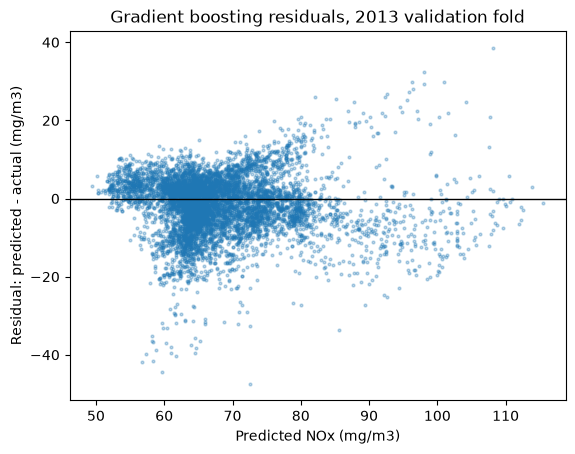

In [6]:
import matplotlib.pyplot as plt

# refits the chosen gradient boosting settings on fold 2 (train 2011-2012, validate 2013)
train_years, val_year = folds[1]
train_fold = df[df.year.isin(train_years)]
val_fold = df[df.year == val_year]
best_gb = HistGradientBoostingRegressor(early_stopping=False, **best_gb_params)
best_gb.fit(train_fold[FEATURES], train_fold[TARGET])

# predicts NOx for 2013 and works out each row's error, positive = overprediction
predictions = best_gb.predict(val_fold[FEATURES])
residuals = predictions - val_fold[TARGET]

# plots residuals against predicted NOx, the line at 0 is a perfect prediction
plt.scatter(predictions, residuals, s=4, alpha=0.3)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Predicted NOx (mg/m3)")
plt.ylabel("Residual: predicted - actual (mg/m3)")
plt.title("Gradient boosting residuals, 2013 validation fold")

# saves the plot to outputs/ before showing it
plt.savefig(OUTPUT_DIR / "gb_residuals_2013.png", dpi=150, bbox_inches="tight")
plt.show()

I plotted gradient boosting's residuals (predicted - actual) against its predicted NOx on the 2013 validation fold, as it was the best model in the results table: it tied network A on CV MAE but had slightly better RMSE and R² and trained much faster. Most points are within about ± 10 mg/m³ of the zero line, with most predictions between 60 and 75 mg/m³.

This suggests the model rarely predicts very low or very high NOx values. However, the residuals aren't evenly spread around zero:
* Predictions below about 60 are mostly above the zero line, meaning the model is overpredicting.
* There is a long tail of large negative residuals reaching down to about -45 or -46, mostly around predictions of 60-75.
* Above 80 there are fewer points and the residuals are more spread out.

This suggests that when actual NOx is high, the model often predicts a more typical value instead, rather than capturing the higher emissions. This matches the underprediction of high NOx values seen in the residual analysis below. One limitation is that this only looks at one validation fold (2013) and one model.

## Residual analysis

In [7]:
# residual analysis: gradient boosting on fold 2 (train 2011-2012, validate 2013)
# uses val_fold, predictions and residuals from the residual plot cell above

# splits the actual 2013 NOx values into 4 ranges, the last one is the high-NOx tail
NOX_RANGE_EDGES = [0, 55, 65, 75, 120]   # mg/m3
nox_ranges = pd.cut(val_fold[TARGET], bins=NOX_RANGE_EDGES)

# for each range: number of rows, average error size and average signed error (positive = overprediction)
error_by_range = pd.DataFrame({
    "Rows": residuals.groupby(nox_ranges, observed=True).size(),
    "MAE": residuals.abs().groupby(nox_ranges, observed=True).mean(),
    "Mean signed error": residuals.groupby(nox_ranges, observed=True).mean(),
})
error_by_range.index.name = "Actual NOx range (mg/m3)"

# every validation row should fall in exactly one range
assert error_by_range["Rows"].sum() == len(val_fold)

# saves the table to outputs/
error_by_range.to_csv(OUTPUT_DIR / "gb_error_by_nox_range_2013.csv")
error_by_range.round(2)

,Rows,MAE,Mean signed error
Actual NOx range (mg/m3),,,
"(0, 55]",559,5.13,5.08
"(55, 65]",2024,4.00,3.46
"(65, 75]",2585,4.72,-2.09
"(75, 120]",1984,8.79,-8.26


## Residual analysis

I split the 2013 validation fold into ranges based on the actual NOx values to see where gradient boosting makes the largest errors. The model performs worst on the higher NOx values, above 75 mg/m³ (1,984 rows), where the MAE is 8.79. This is about double the MAE for 55-65 (4.00) and 65-75 (4.72) (8.79 / 4.00 = 2.2 and 8.79 / 4.72 = 1.9). The signed error also changes depending on the NOx range. The model overpredicts lower values (+5.08 for 55 or below and +3.46 for 55-65), but underpredicts higher values (-2.09 for 65-75 and -8.26 above 75).

This suggests the model pulls predictions towards the middle of the NOx range, meaning it struggles most with the highest values. This is important for responsible use, as underpredicting high emissions is the more harmful error if the model is being used as a backup to an emissions sensor. One limitation is that this only looks at 1 validation fold (2013) and 1 model, this means the same pattern may not apply to the other years or models.


## Draft Conclusion
Conclusion:
The current best model is gradient boosting with learning_rate = 0.05, max_iter = 100 and max_leaf_nodes = 31.

Why I chose it:
* It reduced the baseline CV MAE from 8.15 to 4.75 mg/m³, which is about a 42% improvement.
* It had almost the same CV MAE as network A (4.751 vs 4.746), but slightly better RMSE (6.42 vs 6.50) and R² (0.67 vs 0.66).
* It was much faster to train, taking 0.41 seconds compared to 10.99 seconds for network A.
* Network B performed worse than network A on both folds, with a CV MAE of 5.03.

Based on this, there doesn't seem to be a reason to use the neural network, since it takes much longer to train without giving a clear improvement in accuracy.

Limitations:
* Only two CV folds were used, and the same folds were used for tuning and reporting the scores, so the results may be slightly optimistic.
* The dataset only covers one turbine and doesn't include timestamps.
* The model struggles with high NOx values. Above 75 mg/m³ its MAE is 8.79 and its mean signed error is -8.26, meaning it underpredicts these values. All models also underpredict on average.
* The network results come from a single seed (42), so its near tie with gradient boosting may be down to the random seed.
* The drop in NOx during the 2014-2015 test years hasn't been evaluated yet, so performance on the test set could be worse than the CV results.

Next steps:
* Depending on time, I may:
  * rerun network A with two more seeds (43 and 44) and report the mean ± standard deviation across all three; the mean gives its typical score and the standard deviation shows how much it changes with the seed, so I can see if the tie with gradient boosting is real
  * add linear regression and random forest from my original proposal, scored on the same two folds and metrics
* Then run the final evaluation on the 2014-2015 test years once without any further tuning.
